# Laurence Fishburne y sus colaboradores: un grafo visto como kernel
Análisis y Ciencia de Datos · UNIS · Parte individual · **Nohel Estrada**

Si $B$ es la matriz actores × películas, $A = BB^\top$ cuenta películas compartidas. Es la misma idea que el kernel del
*random forest* de la parte grupal: allá dos filas se parecen si caen en las mismas hojas; aquí dos actores se parecen si
salen en las mismas películas. Cada película juega el papel de una hoja.

**Para correrlo:** basta con el cache de `cache/`. Solo si falta algún JSON hace falta exportar `TMDB_API_KEY`
(no está en el repositorio).

In [1]:
import itertools
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

from graph import Graph
from tmdb_api import TMDBAPIUtils

ACTOR = "Laurence Fishburne"
LIMIT = 5
VENTANA = ("1975-01-01", "2025-12-31")
tmdb = TMDBAPIUtils(cache="cache")

## I.2 La clase `Graph` (en `graph.py`)
Lista de adyacencia `adj[a][b] = peso`. Al agregar $(a,b)$ se actualizan `adj[a][b]` y `adj[b][a]`, así que $(a,b)$ y
$(b,a)$ son la misma arista. Una prueba pequeña:

In [2]:
t = Graph()
for nodo in [(10, "x"), (20, "y"), (30, "z"), (10, "x otra vez")]:
    t.add_node(nodo)
for a, b in [(10, 20), (20, 10), (20, 30)]:
    t.add_edge(a, b)
M, orden = t.adjacency()
print(t.total_nodes(), "nodos,", t.total_edges(), "aristas, mayor grado:", t.max_degree_nodes())
print(orden, "\n", M)

3 nodos, 2 aristas, mayor grado: {20: 2}
[10, 20, 30] 
 [[0. 2. 0.]
 [2. 0. 1.]
 [0. 1. 0.]]


## I.3 `TMDBAPIUtils` (en `tmdb_api.py`)
Cada respuesta se guarda como JSON en `cache/`. `get_movie_cast` filtra `0 ≤ order ≤ limit−1` y quita `exclude_ids`;
`get_movie_credits_for_person` filtra por fecha (el API no lo hace), quita documentales (género 99) y papeles en los
que el actor hace de sí mismo.

In [3]:
encontrado = tmdb.search_person(ACTOR)[0]
SEMILLA = encontrado["id"]
print(f"{encontrado['name']} -> id {SEMILLA}")

Laurence Fishburne -> id 2975


## I.4 Construcción del grafo
Una película **cuenta** para un actor si salió en la ventana 1975–2025 y el actor tiene `order < 5`.

In [4]:
def cuentan(persona):
    # una persona puede aparecer dos veces en la misma película (dos personajes): se cuenta una vez
    unicas = {p["id"]: p for p in tmdb.get_movie_credits_for_person(persona, *VENTANA)
              if p["order"] is not None and p["order"] < LIMIT}
    return list(unicas.values())


def construir_grafo():
    g = Graph()
    g.add_node((SEMILLA, ACTOR))                                   # (a)
    for peli in cuentan(SEMILLA):                                  # (b)
        for actor in tmdb.get_movie_cast(peli["id"], LIMIT, exclude_ids=[SEMILLA]):
            g.add_node((actor["id"], actor["name"]))
    creditos = {n: cuentan(n) for n in g.names}                    # (c)
    por_peli = {}
    for n, pelis in creditos.items():
        for p in pelis:
            por_peli.setdefault(p["id"], {"titulo": f"{p['title']} ({p['release_date'][:4]})", "actores": set()})
            por_peli[p["id"]]["actores"].add(n)
    for info in por_peli.values():
        for a, b in itertools.combinations(sorted(info["actores"]), 2):   # una vez por película y pareja
            g.add_edge(a, b)
    return g, creditos, por_peli


g, creditos, por_peli = construir_grafo()
A, orden = g.adjacency()
pos_de = {n: i for i, n in enumerate(orden)}
grado = {n: len(v) for n, v in g.adj.items()}
print(f"nodos = {g.total_nodes()}, aristas = {g.total_edges()}")
print("mayor grado:", [(g.names[n], d) for n, d in g.max_degree_nodes().items()])
print("pedidos nuevos al API:", tmdb.pedidos)

nodos = 231, aristas = 1187
mayor grado: [('Laurence Fishburne', 230)]
pedidos nuevos al API: 0


In [5]:
pd.DataFrame(sorted(((g.names[n], d, int(A[pos_de[n]].sum())) for n, d in grado.items()), key=lambda r: -r[1])[:10],
             columns=["actor", "grado", "películas compartidas (grado ponderado)"])

,actor,grado,películas compartidas (grado ponderado)
0,Laurence Fishburne,230,252
1,Keanu Reeves,27,44
2,Angela Bassett,27,31
3,Andy Garcia,25,28
4,Kevin Bacon,24,27
5,Sam Neill,23,26
6,Gabriel Byrne,22,25
7,Liam Neeson,22,25
8,Nicolas Cage,21,22
9,Anthony Hopkins,20,21


Para Fishburne cuentan las películas de 1975 (*Cornbread, Earl and Me*, su debut) en adelante: el grafo queda con
**231 actores y 1 187 aristas**. El nodo de mayor grado es él mismo (230 vecinos). Le siguen Keanu Reeves y Angela Bassett
con 27; Reeves tiene el mayor grado ponderado (44) porque repite muchas películas con otros nodos (la trilogía de *Matrix*,
*John Wick*).

## I.5 Visualización

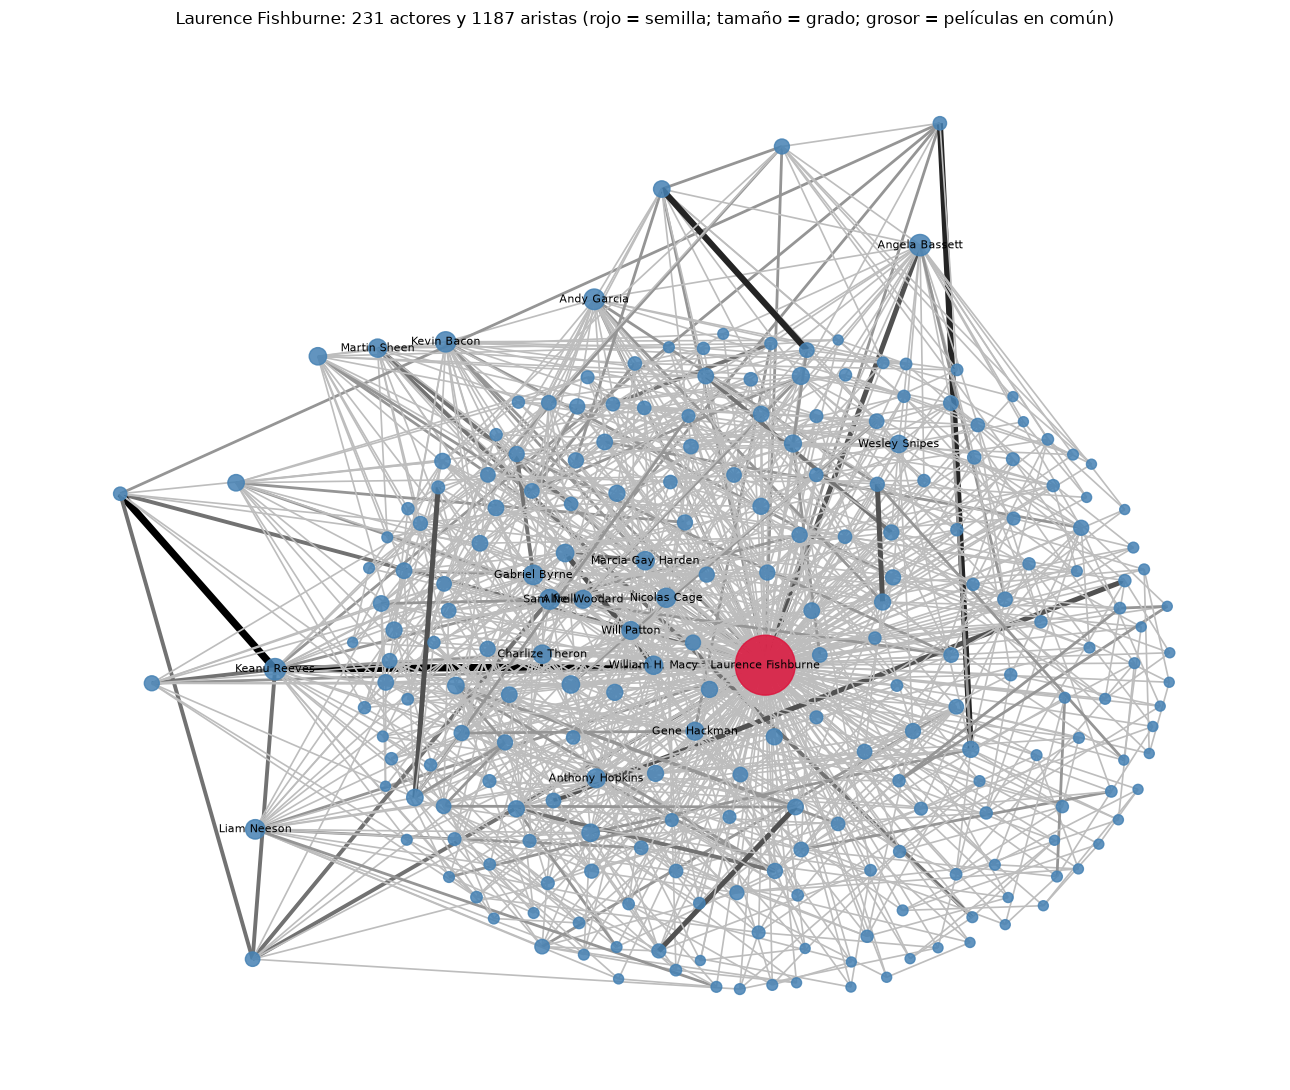

In [6]:
G = nx.from_numpy_array(A)
G = nx.relabel_nodes(G, dict(enumerate(orden)))
coords = nx.kamada_kawai_layout(G)
fig, ax = plt.subplots(figsize=(13, 11))
pesos = np.array([G[u][v]["weight"] for u, v in G.edges])
nx.draw_networkx_edges(G, coords, ax=ax, width=0.4 + 0.8 * pesos, edge_color=pesos, edge_cmap=plt.cm.Greys,
                       edge_vmin=-2, edge_vmax=pesos.max())
nx.draw_networkx_nodes(G, coords, ax=ax, node_size=[20 + 8 * grado[n] for n in G.nodes],
                       node_color=["crimson" if n == SEMILLA else "steelblue" for n in G.nodes], alpha=0.85)
mayores = sorted(grado, key=grado.get, reverse=True)[:18]
nx.draw_networkx_labels(G, coords, {n: g.names[n] for n in mayores}, font_size=8, ax=ax)
ax.set_title(f"{ACTOR}: {g.total_nodes()} actores y {g.total_edges()} aristas (rojo = semilla; tamaño = grado; "
             "grosor = películas en común)")
ax.axis("off")
fig.tight_layout()
fig.savefig("figuras/grafo_fishburne.png", dpi=160)
plt.show()

## I.6 Espectro
$L = D - A$, $L_{sym} = I - D^{-1/2} A D^{-1/2}$ con grados ponderados; valores y vectores propios con `np.linalg.eigh`.

In [7]:
def laplaciano_sym(A, arreglo=True):
    """Si un nodo tiene grado 0, D^{-1/2} se pone en 0 en esa entrada.
    arreglo=False: queda I en esa fila (valor propio 1).
    arreglo=True : se usa L_sym = D^{-1/2}(D - A)D^{-1/2}, que deja la fila en 0 (valor propio 0)."""
    d = A.sum(1)
    r = np.where(d > 0, 1 / np.sqrt(np.where(d > 0, d, 1)), 0.0)
    if arreglo:
        return r[:, None] * (np.diag(d) - A) * r[None, :]
    return np.eye(len(A)) - r[:, None] * A * r[None, :]


def bfs(A):
    """Número de componentes y etiqueta de cada nodo, con una cola hecha a mano."""
    sin_ver = set(range(len(A)))
    etiquetas = np.zeros(len(A), dtype=int)
    k = 0
    while sin_ver:
        inicio = sin_ver.pop()
        cola, i = [inicio], 0
        etiquetas[inicio] = k
        while i < len(cola):
            u = cola[i]; i += 1
            for v in np.nonzero(A[u])[0]:
                if v in sin_ver:
                    sin_ver.remove(v)
                    etiquetas[v] = k
                    cola.append(v)
        k += 1
    return k, etiquetas


s = pos_de[SEMILLA]
resto = np.array([i for i in range(len(orden)) if i != s])
A_menos = A[np.ix_(resto, resto)]
orden_menos = [orden[i] for i in resto]

### (a) Componentes conexas

In [8]:
for etiqueta, M in [("con la semilla", A), ("sin la semilla", A_menos)]:
    k_bfs, _ = bfs(M)
    sin_arreglo = int(np.sum(np.linalg.eigvalsh(laplaciano_sym(M, arreglo=False)) < 1e-8))
    con_arreglo = int(np.sum(np.linalg.eigvalsh(laplaciano_sym(M)) < 1e-8))
    print(f"{etiqueta:15s}: BFS = {k_bfs:3d} | λ<1e-8 sin arreglo = {sin_arreglo:3d} | con arreglo = {con_arreglo:3d} "
          f"| aislados = {int(np.sum(M.sum(1) == 0)):3d} | networkx = {nx.number_connected_components(nx.from_numpy_array(M))}")

con la semilla : BFS =   1 | λ<1e-8 sin arreglo =   1 | con arreglo =   1 | aislados =   0 | networkx = 1
sin la semilla : BFS =   1 | λ<1e-8 sin arreglo =   1 | con arreglo =   1 | aislados =   0 | networkx = 1


En este grafo las dos cuentas coinciden: con y sin la semilla hay **una sola componente** y **ningún aislado**. Todos los
coprotagonistas de Fishburne comparten al menos otra película con alguien del grafo, así que quitarlo no deja a nadie suelto.

Aun así, la función maneja el caso general. Al quitar la semilla, un actor que solo compartía película con ella queda con grado 0. Poner $0$ en
$D^{-1/2}_{ii}$ hace que la fila $i$ de $D^{-1/2}AD^{-1/2}$ sea cero, y entonces $L_{sym}$ tiene un **1** en la diagonal:
el nodo aislado produce el valor propio 1 y desaparece del conteo de ceros (cuenta "BFS − aislados"). Arreglo: escribir
$L_{sym}=D^{-1/2}(D-A)D^{-1/2}$, que es igual cuando $d_i>0$ y deja la fila del aislado en cero: valor propio 0 y una
componente más, que es lo correcto.

### (b) Brecha espectral

λ2 con semilla: 0.281753 | λ2 sin semilla: 0.062037
verificación networkx: 0.281753


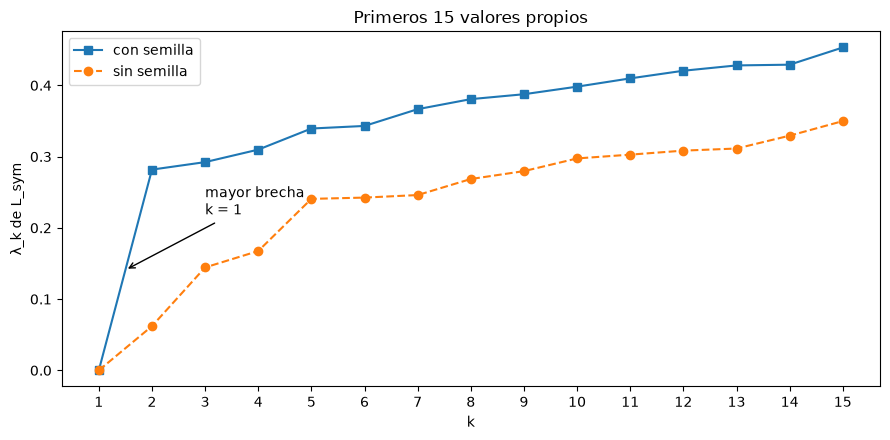

brechas con semilla: [0.2818 0.0105 0.0175 0.0296 0.0036 0.0235 0.0141 0.0069 0.0106 0.0116
 0.0107 0.0075 0.001  0.0242] -> k = 1
brechas sin semilla: [0.062  0.0824 0.0231 0.0732 0.0018 0.0036 0.0225 0.0111 0.0178 0.0053
 0.0056 0.0029 0.0181 0.0204] -> k = 2


In [9]:
lam, vec = np.linalg.eigh(laplaciano_sym(A))
lam_m, vec_m = np.linalg.eigh(laplaciano_sym(A_menos))
print("λ2 con semilla:", round(lam[1], 6), "| λ2 sin semilla:", round(lam_m[1], 6))
print("verificación networkx:", round(sorted(nx.normalized_laplacian_spectrum(G, weight="weight"))[1], 6))

brechas = np.diff(lam[:15])
k_brecha = int(np.argmax(brechas)) + 1
brechas_m = np.diff(lam_m[:15])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(1, 16), lam[:15], "s-", label="con semilla")
ax.plot(range(1, 16), lam_m[:15], "o--", label="sin semilla")
ax.annotate(f"mayor brecha\nk = {k_brecha}", xy=(k_brecha + 0.5, (lam[k_brecha - 1] + lam[k_brecha]) / 2),
            xytext=(k_brecha + 2, lam[k_brecha] * 0.6 + 0.05), arrowprops=dict(arrowstyle="->"))
ax.set_xticks(range(1, 16)); ax.set_xlabel("k"); ax.set_ylabel("λ_k de L_sym"); ax.legend()
ax.set_title("Primeros 15 valores propios")
fig.tight_layout(); fig.savefig("figuras/valores_propios.png", dpi=150); plt.show()
print("brechas con semilla:", np.round(brechas, 4), "-> k =", k_brecha)
print("brechas sin semilla:", np.round(brechas_m, 4), "-> k =", int(np.argmax(brechas_m)) + 1)

**Lectura.** Con la semilla, $\lambda_2 = 0.282$ y la mayor brecha está entre $\lambda_1$ y $\lambda_2$ ($k=1$): el grafo es
conexo y ninguna parte se separa con claridad. Sin la semilla, $\lambda_2$ cae a **0.062**: el grafo sigue conexo, pero quitar
al *hub* deja ver lo débil que era la unión entre grupos, y la mayor brecha pasa a $k=2$.

**¿Por qué con la semilla siempre es conexo?** Por construcción, en (b) todo actor entra por compartir una película con
Fishburne, y en (c) esa película crea la arista con él. Aun así la brecha puede delatar comunidades: $L_{sym}$ divide cada
arista entre $\sqrt{d_id_j}$, y como el grado de la semilla es enorme, sus aristas pesan poco. Los grupos que solo se tocan
a través de ella aparecen casi como componentes separadas (valores propios pequeños, seguidos de un salto). Como aquí la mayor
brecha es $k=1$, para agrupar usamos la siguiente mayor brecha ($k = 4$, entre $\lambda_4$ y $\lambda_5$).

### (c) Clustering espectral

In [10]:
k = k_brecha if k_brecha > 1 else int(np.argmax(brechas[1:])) + 2
X = vec[:, :k] / np.linalg.norm(vec[:, :k], axis=1, keepdims=True)
grupos = KMeans(n_clusters=k, n_init=50, random_state=1).fit_predict(X)
filas = []
for c in range(k):
    gente = [orden[i] for i in np.where(grupos == c)[0]]
    conteo = Counter(p["id"] for n in gente for p in creditos[n])
    filas.append({"comunidad": c, "n": len(gente),
                  "3 de mayor grado": "; ".join(g.names[n] for n in sorted(gente, key=grado.get, reverse=True)[:3]),
                  "3 películas más repetidas": "; ".join(f"{por_peli[p]['titulo']} [{v}]" for p, v in conteo.most_common(3))})
with pd.option_context("display.max_colwidth", 130):
    display(pd.DataFrame(filas).set_index("comunidad"))

,n,3 de mayor grado,3 películas más repetidas
comunidad,,,
0,62,Laurence Fishburne; Keanu Reeves; Nicolas Cage,The Matrix Reloaded (2003) [5]; The Matrix Revolutions (2003) [5]; Osmosis Jones (2001) [5]
1,98,Andy Garcia; Kevin Bacon; Sam Neill,All the King's Men (2006) [4]; The Death and Life of Bobby Z (2007) [4]; Passengers (2016) [4]
2,53,Angela Bassett; Wesley Snipes; Blair Underwood,Akeelah and the Bee (2006) [4]; What's Love Got to Do with It (1993) [4]; The Snowy Day (2016) [4]
3,18,Alfre Woodard; Clarence Williams III; Jeff Goldblum,"The House of Dies Drear (1984) [4]; Cornbread, Earl and Me (1975) [4]; For Us, the Living: The Story of Medgar Evers (1983) [4]"


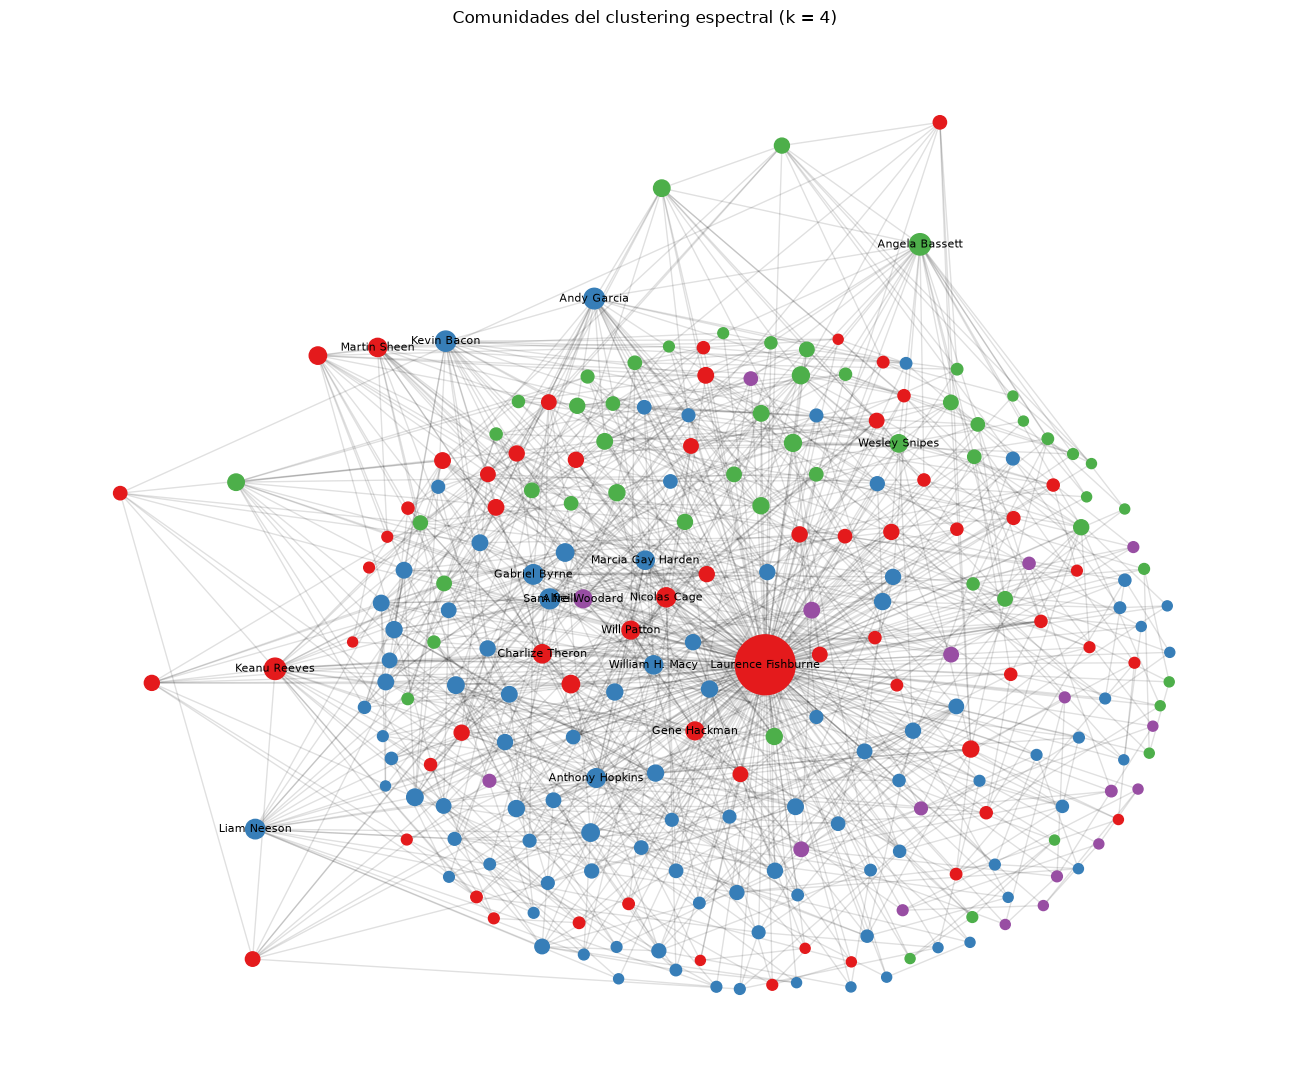

In [11]:
fig, ax = plt.subplots(figsize=(13, 11))
nx.draw_networkx_edges(G, coords, ax=ax, alpha=0.12)
nx.draw_networkx_nodes(G, coords, ax=ax, node_size=[20 + 8 * grado[n] for n in G.nodes],
                       node_color=[grupos[pos_de[n]] for n in G.nodes], cmap="Set1", vmin=0, vmax=8)
nx.draw_networkx_labels(G, coords, {n: g.names[n] for n in mayores}, font_size=8, ax=ax)
ax.set_title(f"Comunidades del clustering espectral (k = {k})"); ax.axis("off")
fig.tight_layout(); fig.savefig("figuras/comunidades_fishburne.png", dpi=160); plt.show()

**Las comunidades sí corresponden a algo real:**
* **Franquicia:** Fishburne, Keanu Reeves y su grupo; lo que más se repite es *The Matrix Reloaded* y *Revolutions*.
* **Época:** el grupo de Alfre Woodard y Clarence Williams III reúne su primera etapa (*Cornbread, Earl and Me*, 1975;
  *For Us, the Living*, 1983; *The House of Dies Drear*, 1984), casi todo cine y televisión afroamericanos de los 70 y 80.
* **Cine afroamericano de los 90 y 2000:** Angela Bassett, Wesley Snipes y Blair Underwood (*What's Love Got to Do with It*,
  *Akeelah and the Bee*).
* **Thrillers y dramas de Hollywood:** el grupo más grande (Andy Garcia, Kevin Bacon, Sam Neill; *All the King's Men*).

### (d) Vector de Fiedler

In [12]:
_, etq = bfs(A_menos)
grande = np.where(etq == np.bincount(etq).argmax())[0]
Ac = A_menos[np.ix_(grande, grande)]
lam_c, vec_c = np.linalg.eigh(laplaciano_sym(Ac))
signo = vec_c[:, 1] > 0
cortes = [(i, j) for i, j in zip(*np.nonzero(np.triu(Ac))) if signo[i] != signo[j]]
print(f"componente más grande sin semilla: {len(grande)} actores; λ2 = {lam_c[1]:.5f}")
print(f"positivos: {signo.sum()}, negativos: {(~signo).sum()}, aristas que cruzan: {len(cortes)} "
      f"de {int(np.count_nonzero(np.triu(Ac)))}")
ids_c = [orden_menos[i] for i in grande]
for nombre_lado, mask in [("positivo", signo), ("negativo", ~signo)]:
    gente = [ids_c[i] for i in np.where(mask)[0]]
    top = sorted(gente, key=grado.get, reverse=True)[:6]
    pel = Counter(p["id"] for n in gente for p in creditos[n]).most_common(6)
    print(f"\nlado {nombre_lado}:", ", ".join(g.names[n] for n in top))
    print("   ", "; ".join(f"{por_peli[p]['titulo']} [{v}]" for p, v in pel))
print("\nalgunas aristas del corte:", "; ".join(f"{g.names[ids_c[i]]} – {g.names[ids_c[j]]}" for i, j in cortes[:12]))

componente más grande sin semilla: 230 actores; λ2 = 0.06204
positivos: 15, negativos: 215, aristas que cruzan: 44 de 957

lado positivo: Jim Belushi, Arnold Schwarzenegger, Peter Boyle, Olivia Cooke, Ed O'Ross, David Ogden Stiers
    Red Heat (1988) [4]; The Signal (2014) [4]; Pee-wee's Playhouse Christmas Special (1988) [4]; Hoodwinked! (2005) [2]; K-9: P.I. (2002) [2]; Royce (1994) [2]

lado negativo: Keanu Reeves, Angela Bassett, Andy Garcia, Kevin Bacon, Sam Neill, Gabriel Byrne
    Apocalypse Now (1979) [4]; Mystic River (2003) [4]; All the King's Men (2006) [4]; Quicksilver (1986) [4]; The Matrix (1999) [4]; The Matrix Reloaded (2003) [4]

algunas aristas del corte: Martin Sheen – Blu Mankuma; Frederic Forrest – Peter Boyle; Marcia Gay Harden – Jim Belushi; Keanu Reeves – Jim Belushi; Hugo Weaving – Brenton Thwaites; Morris Chestnut – Peter Boyle; Clarence Williams III – Ed O'Ross; Vanessa Williams – Arnold Schwarzenegger; Andy Garcia – Beau Knapp; Gabriel Luna – Arnold Schwarze

**El corte de Fiedler separa una periferia.** El lado positivo tiene solo **15 actores**: el elenco de *Red Heat* (1988;
Schwarzenegger, Jim Belushi, Peter Boyle), *The Signal* (2014) y un especial de *Pee-wee's Playhouse*. El lado negativo es el
resto, 215 actores, con *Matrix*, *Mystic River* y *Apocalypse Now*. Solo **44 de 957 aristas** cruzan. Fiedler busca el
corte más barato en proporción al tamaño de cada lado, así que aquí no parte el grafo en dos mitades: aísla el grupo que
menos se conecta con el centro.

### (e) Centralidad

In [13]:
valores, vectores = np.linalg.eigh(A)
v1 = np.abs(vectores[:, np.argmax(np.abs(valores))])
comp = max(nx.connected_components(G), key=len)          # networkx exige un grafo conexo
verif = nx.eigenvector_centrality_numpy(G.subgraph(comp), weight="weight")
print("correlación con networkx (componente más grande):",
      np.corrcoef([v1[pos_de[n]] for n in comp], [verif[n] for n in comp])[0, 1].round(6))
pd.DataFrame({
    "top 5 por grado": [f"{g.names[n]} ({grado[n]})" for n in sorted(grado, key=grado.get, reverse=True)[:5]],
    "top 5 por vector propio": [f"{g.names[orden[i]]} ({v1[i] / v1.max():.3f})" for i in np.argsort(-v1)[:5]],
})

correlación con networkx (componente más grande): 1.0


,top 5 por grado,top 5 por vector propio
0,Laurence Fishburne (230),Laurence Fishburne (1.000)
1,Keanu Reeves (27),Keanu Reeves (0.483)
2,Angela Bassett (27),Carrie-Anne Moss (0.304)
3,Andy Garcia (25),Hugo Weaving (0.273)
4,Kevin Bacon (24),Angela Bassett (0.255)


**Grado contra vector propio.** Coinciden 3 de 5 (Fishburne, Reeves, Bassett). Por grado entran Andy Garcia y Kevin Bacon,
que colaboraron con muchos actores distintos; por vector propio entran **Carrie-Anne Moss y Hugo Weaving**, que tienen menos
vecinos, pero comparten tres o cuatro películas con Fishburne y con Reeves (la trilogía de *Matrix*). El grado mide
**cuántos** contactos tiene un actor. La centralidad de vector propio mide **qué tan importantes** son esos contactos y
cuántas películas comparte con ellos, porque usa los pesos y se refuerza a sí misma ($Av=\lambda v$).